In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/powerlifting.db")

query = """
WITH numeradas AS (
    SELECT Name, Sex, Dots,
           ROW_NUMBER() OVER (PARTITION BY Name, Sex ORDER BY Date) AS nro,
           LAG(Dots) OVER (PARTITION BY Name, Sex ORDER BY Date) AS dots_anterior
    FROM powerlifting
)
SELECT nro AS nro_competencia,
       COUNT(*) AS levantadores,
       ROUND(AVG(Dots), 1) AS dots_promedio,
       ROUND(AVG(Dots - dots_anterior), 1) AS cambio_promedio
FROM numeradas
WHERE nro <= 10
GROUP BY nro
ORDER BY nro
"""

prog = pd.read_sql_query(query, conn)
prog

,nro_competencia,levantadores,dots_promedio,cambio_promedio
0,1,790161,312.6,NaN
1,2,431988,329.7,17.9
2,3,292555,341.5,11.3
3,4,211172,351.2,8.2
4,5,158354,359.1,6.6
5,6,122133,365.4,5.4
6,7,96751,370.8,4.5
7,8,77669,375.6,3.8
8,9,62862,379.8,3.0
9,10,51531,383.9,2.7


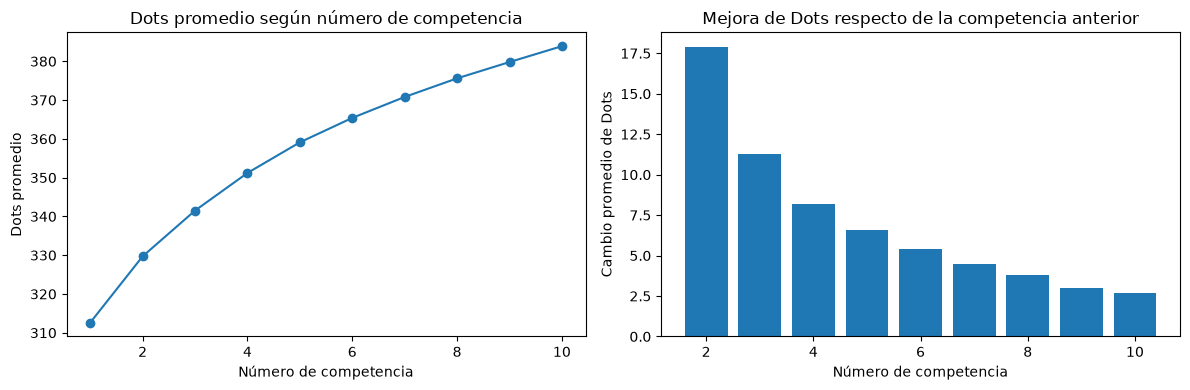

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(prog["nro_competencia"], prog["dots_promedio"], marker="o")
ax[0].set_title("Dots promedio según número de competencia")
ax[0].set_xlabel("Número de competencia")
ax[0].set_ylabel("Dots promedio")

cambio = prog[prog["nro_competencia"] >= 2]
ax[1].bar(cambio["nro_competencia"], cambio["cambio_promedio"])
ax[1].set_title("Mejora de Dots respecto de la competencia anterior")
ax[1].set_xlabel("Número de competencia")
ax[1].set_ylabel("Cambio promedio de Dots")

plt.tight_layout()
plt.savefig("../images/progresion.png", dpi=150)
plt.show()